# TP Jour 3 — Spark SQL Avancé, Rigueur Statistique & Couche Gold

### Objectifs de la séance
1. Diagnostiquer l'**asymétrie (`SKEWNESS`)** de vos variables quantitatives et justifier l'emploi d'indicateurs robustes (**Médiane `PERCENTILE_APPROX`**, **IQR `P75 - P25`**, **P90**) plutôt que la seule moyenne arithmétique.
2. Écrire des requêtes **Spark SQL avancées** mobilisant des CTE (`WITH ...`) et des **fonctions de fenêtrage** (`DENSE_RANK`, `ROW_NUMBER`, cumul de **Pareto**, variation temporelle **`LAG`**).
3. Construire au moins **2 à 3 tables agrégées métier dans `/lakehouse/gold/`** prêtes à alimenter votre Dashboard Streamlit à faible latence.
4. Éviter le *Small Files Problem* sur HDFS et compacter votre table Silver avec `OPTIMIZE`.

In [16]:
from pyspark.sql import SparkSession
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J3_Analytics_SQL_Gold")
    .getOrCreate()
)

SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"
spark.read.format("delta").load(SILVER_MAIN_PATH).createOrReplaceTempView("v_silver")
print("Lignes disponibles dans v_silver :", spark.sql("SELECT COUNT(*) FROM v_silver").first()[0])
spark.sql("SELECT * FROM v_silver WHERE cancelled = 0 AND arrival_delay IS NOT NULL").createOrReplaceTempView("v_observed")
print("Les analyses de retard portent sur les vols non annulés avec retard à l'arrivée connu.")

Lignes disponibles dans v_silver : 5819079
Les analyses de retard portent sur les vols non annulés avec retard à l'arrivée connu.


## 1. Analyse d'Asymétrie : Moyenne vs Médiane & Écart Interquartile (IQR)

### Exercice 1.1 — Étudier la distribution de votre métrique quantitative principale
Écrivez une requête Spark SQL sur `v_silver` calculant sur votre variable continue principale :
- `COUNT(*)`, `AVG(...)`, `STDDEV(...)`, `SKEWNESS(...)`
- Les quantiles `P25`, `P50` (médiane), `P75`, `P90`, `P95` via `PERCENTILE_APPROX(col, q)` et `MAX(...)`.

Rédigez ensuite en Markdown **votre interprétation statistique** (écart moyenne/médiane, impact des valeurs extrêmes, choix de l'indicateur retenu pour votre dashboard).

In [17]:
df_dist_summary = spark.sql("""
SELECT COUNT(*) AS n_vols, AVG(arrival_delay) AS moyenne,
       STDDEV(arrival_delay) AS ecart_type, SKEWNESS(arrival_delay) AS asymetrie,
       PERCENTILE_APPROX(arrival_delay, 0.25, 10000) AS p25,
       PERCENTILE_APPROX(arrival_delay, 0.50, 10000) AS mediane,
       PERCENTILE_APPROX(arrival_delay, 0.75, 10000) AS p75,
       PERCENTILE_APPROX(arrival_delay, 0.90, 10000) AS p90,
       PERCENTILE_APPROX(arrival_delay, 0.95, 10000) AS p95,
       MAX(arrival_delay) AS maximum
FROM v_observed
""")
df_dist_summary.show(truncate=False)
distribution = df_dist_summary.first()
if distribution.n_vols < 2 or distribution.asymetrie is None:
    raise ValueError("Distribution insuffisante pour interpréter l'asymétrie.")
print(f"Moyenne : {distribution.moyenne:.2f} min ; médiane : {distribution.mediane} min ; IQR : {distribution.p75 - distribution.p25} min ; asymétrie : {distribution.asymetrie:.2f}.")

+-------+-----------------+-----------------+-----------------+---+-------+---+---+---+-------+
|n_vols |moyenne          |ecart_type       |asymetrie        |p25|mediane|p75|p90|p95|maximum|
+-------+-----------------+-----------------+-----------------+---+-------+---+---+---+-------+
|5714008|4.407057357987598|39.27129709388639|6.502894504785052|-13|-5     |8  |34 |66 |1971   |
+-------+-----------------+-----------------+-----------------+---+-------+---+---+---+-------+



Moyenne : 4.41 min ; médiane : -5 min ; IQR : 21 min ; asymétrie : 6.50.


**Justification statistique :** une asymétrie positive et une moyenne supérieure à la médiane indiquent que les retards élevés tirent la moyenne vers le haut. La médiane et l'IQR décrivent le vol typique et sa dispersion sans être dominés par les extrêmes ; P90/P95 rendent visibles les retards importants. Les résultats exacts sont affichés ci-dessus.

---
## 2. Table Gold #1 : Classement Métier & Loi de Pareto (`OVER ORDER BY ...`)

### Exercice 2.1 — Agrégation par segment/catégorie + Courbe cumulée de Pareto
Construisez en Spark SQL une première table Gold agrégée par une dimension métier pertinente de votre dataset incluant :
- Le volume d'observations, le total et les indicateurs robustes (**médiane**, **IQR**).
- Le rang via `DENSE_RANK() OVER (ORDER BY ... DESC)`.
- Le pourcentage cumulé du total (**analyse de Pareto 80/20**) via :
  `SUM(metric_total) OVER (ORDER BY metric_total DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) / SUM(metric_total) OVER ()`.

Ici, le Pareto porte sur la somme des **minutes de retard positives** : une arrivée en avance contribue zéro. Ce choix évite que les avances annulent les retards et conserve un cumul croissant. Les vols annulés et les retards inconnus sont exclus de ce calcul.

In [18]:
GOLD_PARETO_PATH = "/lakehouse/gold/flights_airline_pareto"
df_gold_1 = spark.sql("""
WITH grouped AS (
  SELECT airline, MAX(airline_name) AS airline_name, COUNT(*) AS n_vols,
         SUM(GREATEST(arrival_delay, 0)) AS minutes_retard,
         AVG(arrival_delay) AS moyenne, PERCENTILE_APPROX(arrival_delay, 0.25, 10000) AS p25,
         PERCENTILE_APPROX(arrival_delay, 0.50, 10000) AS mediane,
         PERCENTILE_APPROX(arrival_delay, 0.75, 10000) AS p75,
         PERCENTILE_APPROX(arrival_delay, 0.90, 10000) AS p90,
         CAST(100 AS DOUBLE) * AVG(CASE WHEN arrival_delay >= 15 THEN CAST(1 AS DOUBLE) ELSE CAST(0 AS DOUBLE) END) AS retard_pct
  FROM v_observed GROUP BY airline
), ranked AS (
  SELECT *, p75 - p25 AS iqr,
         DENSE_RANK() OVER (ORDER BY minutes_retard DESC) AS rang,
         SUM(minutes_retard) OVER (ORDER BY minutes_retard DESC, airline ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cumul,
         SUM(minutes_retard) OVER () AS total
  FROM grouped
)
SELECT airline, airline_name, n_vols, minutes_retard, moyenne, p25, mediane, p75, p90, iqr, retard_pct, rang,
       CASE WHEN total > 0 THEN CAST(100 AS DOUBLE) * cumul / total END AS pareto_pct
FROM ranked
""")
df_gold_1.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_PARETO_PATH)
df_gold_1.orderBy("rang", "airline").show(15, truncate=False)

26/11/19 12:07:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:07:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:07:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:07:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:07:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:07:55 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 1

+-------+----------------------------+-------+--------------+-------------------+---+-------+---+---+---+------------------+----+------------------+
|airline|airline_name                |n_vols |minutes_retard|moyenne            |p25|mediane|p75|p90|iqr|retard_pct        |rang|pareto_pct        |
+-------+----------------------------+-------+--------------+-------------------+---+-------+---+---+---+------------------+----+------------------+
|WN     |Southwest Airlines Co.      |1242403|13849257      |4.3749636792570525 |-12|-4     |8  |33 |20 |19.04583295436344 |1   |20.041363541663607|
|AA     |American Airlines Inc.      |712935 |8611910       |3.4513721447256764 |-15|-6     |7  |33 |22 |18.273615406734134|2   |32.503723009618334|
|DL     |Delta Air Lines Inc.        |870275 |8046301       |0.18675361236390797|-15|-8     |3  |22 |18 |13.561575364109046|3   |44.14758545701543 |
|EV     |Atlantic Southeast Airlines |554752 |7504821       |6.585378691739733  |-12|-4     |9  |39 |21 |1

26/11/19 12:08:09 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:09 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:09 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:09 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:09 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:09 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


## 3. Table Gold #2 : Dynamique Temporelle & Croissance avec `LAG()`

### Exercice 3.1 — Série temporelle et taux d'évolution période-sur-période
Agrégez votre table `v_silver` selon son axe temporel (jour, semaine, mois ou année selon votre sujet) et utilisez la fonction de fenêtrage **`LAG(metric, 1) OVER (ORDER BY periode)`** (ou une moyenne glissante `AVG(...) OVER (ORDER BY periode ROWS BETWEEN ... PRECEDING AND CURRENT ROW)`) pour mesurer la dynamique d'évolution.

Sauvegardez le résultat dans `/lakehouse/gold/<nom_gold_2>`.

In [19]:
GOLD_TIME_PATH = "/lakehouse/gold/flights_monthly"
df_gold_2 = spark.sql("""
WITH monthly AS (
  SELECT DATE_TRUNC('MONTH', flight_date) AS mois, COUNT(*) AS n_vols,
         AVG(arrival_delay) AS moyenne,
         PERCENTILE_APPROX(arrival_delay, 0.50, 10000) AS mediane,
         CAST(100 AS DOUBLE) * AVG(CASE WHEN arrival_delay >= 15 THEN CAST(1 AS DOUBLE) ELSE CAST(0 AS DOUBLE) END) AS retard_pct
  FROM v_observed GROUP BY DATE_TRUNC('MONTH', flight_date)
), previous AS (
  SELECT *, LAG(n_vols) OVER (ORDER BY mois) AS vols_mois_precedent FROM monthly
)
SELECT *, CASE WHEN vols_mois_precedent > 0 THEN CAST(100 AS DOUBLE) * (n_vols - vols_mois_precedent) / vols_mois_precedent END AS evolution_vols_pct
FROM previous
""")
df_gold_2.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_TIME_PATH)
df_gold_2.orderBy("mois").show(20, truncate=False)

26/11/19 12:08:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 1

+-------------------+------+-------------------+-------+------------------+-------------------+-------------------+
|mois               |n_vols|moyenne            |mediane|retard_pct        |vols_mois_precedent|evolution_vols_pct |
+-------------------+------+-------------------+-------+------------------+-------------------+-------------------+
|2015-01-01 00:00:00|457013|5.813582983416227  |-4     |20.995245211842988|NULL               |NULL               |
|2015-02-01 00:00:00|407663|8.320500020850556  |-3     |23.347470827619873|457013             |-10.798379914794547|
|2015-03-01 00:00:00|492138|4.92067265685641   |-4     |19.395372842576673|407663             |20.721772640636996 |
|2015-04-01 00:00:00|479251|3.1631900611579318 |-5     |17.16157086787508 |492138             |-2.6185744648858655|
|2015-05-01 00:00:00|489641|4.485018615679651  |-5     |18.308311599723062|479251             |2.1679662640244883 |
|2015-06-01 00:00:00|492847|9.601590351569554  |-3     |23.4843673594442

26/11/19 12:08:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:08:16 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


## 4. Table Gold #3 (Axe complémentaire libre) & Compaction `OPTIMIZE`

### Exercice 4.1 — Produire un 3e axe d'analyse (`ROW_NUMBER() OVER (PARTITION BY ...)`) et compacter Silver
1. Créez une 3e table Gold répondant à une question spécifique de votre problématique (ex. top sous-catégorie par région/groupe via `ROW_NUMBER() OVER (PARTITION BY groupe ORDER BY ... DESC) = 1`).
2. Exécutez `OPTIMIZE delta.'{SILVER_MAIN_PATH}'`. Les nombreux petits fichiers augmentent les métadonnées gérées par le NameNode et le nombre de tâches ; la compaction regroupe les fichiers sans changer les lignes. Les anciennes versions restent disponibles tant qu'elles ne sont pas supprimées par une opération de maintenance.

In [20]:
GOLD_AIRPORT_PATH = "/lakehouse/gold/flights_airline_top_origin"
df_gold_3 = spark.sql("""
WITH grouped AS (
  SELECT airline, origin_airport, MAX(origin_airport_name) AS airport_name,
         COUNT(*) AS n_vols, PERCENTILE_APPROX(arrival_delay, 0.50, 10000) AS mediane
  FROM v_observed GROUP BY airline, origin_airport
), ranked AS (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY airline ORDER BY n_vols DESC, origin_airport) AS position
  FROM grouped
)
SELECT * FROM ranked WHERE position = 1
""")
df_gold_3.coalesce(1).write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_AIRPORT_PATH)
df_gold_3.orderBy("airline").show(20, truncate=False)

silver_delta = DeltaTable.forPath(spark, SILVER_MAIN_PATH)
before_files = silver_delta.detail().select("numFiles").first()[0]
spark.conf.set("spark.databricks.delta.optimize.maxFileSize", str(128 * 1024 * 1024))
spark.sql(f"OPTIMIZE delta.`{SILVER_MAIN_PATH}`").show(truncate=False)
after_files = silver_delta.detail().select("numFiles").first()[0]
print(f"Fichiers Silver actifs : {before_files} avant, {after_files} après OPTIMIZE.")

+-------+--------------+----------------------------------------------------------------------+------+-------+--------+
|airline|origin_airport|airport_name                                                          |n_vols|mediane|position|
+-------+--------------+----------------------------------------------------------------------+------+-------+--------+
|AA     |DFW           |Dallas/Fort Worth International Airport                               |131159|-5     |1       |
|AS     |SEA           |Seattle-Tacoma International Airport                                  |49806 |-3     |1       |
|B6     |JFK           |John F. Kennedy International Airport (New York International Airport)|39587 |-5     |1       |
|DL     |ATL           |Hartsfield-Jackson Atlanta International Airport                      |220400|-7     |1       |
|EV     |IAH           |George Bush Intercontinental Airport                                  |57074 |-3     |1       |
|F9     |DEN           |Denver Internati

+------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|path                                                  |metrics                                                                                                                                                                                               |
+------------------------------------------------------+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|hdfs://namenode:9000/lakehouse/silver/flights_enriched|{5, 50, {117942688, 128266253, 1.249525982E8, 5, 624762991}, {11430259, 59578823, 1.271549014E7, 50, 635774507}, 1, NULL, NULL, 5, 1, 50, 0, false, 0, 0, 1795090130465, 0, 16, 

## 5. Analyse du trafic aérien et des retards

### Question métier
Cette section étudie si le volume de vols programmés est associé au taux de retard au départ. `traffic_volume` mesure le nombre de vols programmés dans un créneau aéroport–jour–heure, y compris les vols annulés. `delay_rate` ne porte que sur les vols non annulés dont le retard au départ est connu.

In [21]:
# Vérification du schéma Silver avant toute agrégation
silver_df = spark.read.format("delta").load(SILVER_MAIN_PATH)
silver_schema = dict((field.name, field.dataType.simpleString()) for field in silver_df.schema.fields)
required_columns = [
    "origin_airport", "flight_date", "scheduled_departure",
    "departure_delay", "cancelled"
]
missing_columns = [column for column in required_columns if column not in silver_schema]
print("Schéma des colonnes requises :")
for column in required_columns:
    print(f"  {column}: {silver_schema.get(column, 'ABSENTE')}")
if missing_columns:
    raise ValueError(f"Colonnes Silver absentes : {missing_columns}")

from pyspark.sql import functions as F

# Normalisation locale défensive : ne présumer ni le type de la date ni celui de l'heure programmée.
scheduled_raw = F.trim(F.col("scheduled_departure").cast("string"))
scheduled_digits = F.regexp_replace(scheduled_raw, r"\.0+$", "")
scheduled_hhmm = F.lpad(scheduled_digits, 4, "0")

# Vérification réelle de la valeur spéciale 2400 avant toute modification de date.
value_2400 = (scheduled_hhmm == "2400") | (scheduled_raw.rlike(r"^24:00$"))
count_2400 = silver_df.where(value_2400).count()
print(f"Nombre de lignes scheduled_departure égales à 2400 : {count_2400}")

date_type = silver_df.schema["flight_date"].dataType.simpleString()
if date_type in ("date", "timestamp"):
    flight_date_base = F.to_date(F.col("flight_date"))
else:
    flight_date_base = F.coalesce(
        F.to_date(F.col("flight_date").cast("string"), "yyyy-MM-dd"),
        F.to_date(F.col("flight_date").cast("string"), "yyyyMMdd")
    )

if count_2400 > 0:
    # 2400 signifie minuit en fin de journée : 00 heure du jour suivant,
    # uniquement dans cette vue locale d'analyse, sans modifier le Silver.
    flight_date_normalized = F.when(value_2400, F.date_add(flight_date_base, 1)).otherwise(flight_date_base)
    print("2400 détecté : conversion locale en 00:00 et date du jour suivant.")
else:
    flight_date_normalized = flight_date_base
    print("2400 absent : aucune conversion spéciale appliquée.")

valid_hhmm = scheduled_hhmm.rlike(r"^(?:[01][0-9]|2[0-3])[0-5][0-9]$")
hhmm_hour = F.when(valid_hhmm, F.substring(scheduled_hhmm, 1, 2).cast("int"))

# Prise en charge secondaire d'un format texte avec les deux-points (HH:MM).
colon_hour = F.regexp_extract(scheduled_raw, r"([01]?[0-9]|2[0-3]):([0-5][0-9])", 1)
colon_hour = F.when(colon_hour != "", colon_hour.cast("int"))
# 2400 est transformé en heure 0; les autres valeurs restent dans le format actuel.
scheduled_hour = F.when(value_2400, F.lit(0)).otherwise(F.coalesce(hhmm_hour, colon_hour)).cast("int")

departure_delay_numeric = F.col("departure_delay").cast("double")
cancelled_text = F.lower(F.trim(F.regexp_replace(F.col("cancelled").cast("string"), r"\.0+$", "")))
is_cancelled = cancelled_text.isin("1", "true", "t", "yes", "y")

normalized_silver_all = silver_df.select(
    F.trim(F.col("origin_airport").cast("string")).alias("origin_airport"),
    flight_date_normalized.alias("flight_date"),
    scheduled_hour.alias("scheduled_hour"),
    is_cancelled.alias("is_cancelled"),
    departure_delay_numeric.alias("departure_delay_numeric")
)

normalized_silver = normalized_silver_all.filter(
    F.col("origin_airport").isNotNull() &
    (F.length(F.col("origin_airport")) > 0) &
    F.col("flight_date").isNotNull() &
    F.col("scheduled_hour").isNotNull()
)
normalized_silver.createOrReplaceTempView("v_silver_traffic_normalized")

GOLD_TRAFFIC_PATH = "/lakehouse/gold/flights_airport_traffic_delays"
df_airport_traffic_delays = spark.sql("""
SELECT
  origin_airport,
  flight_date,
  scheduled_hour,
  COUNT(*) AS traffic_volume,
  SUM(CASE WHEN NOT is_cancelled AND departure_delay_numeric IS NOT NULL THEN 1 ELSE 0 END) AS observed_flights,
  SUM(CASE WHEN NOT is_cancelled AND departure_delay_numeric IS NOT NULL
                  AND departure_delay_numeric >= 15 THEN 1 ELSE 0 END) AS delayed_flights,
  CASE WHEN SUM(CASE WHEN NOT is_cancelled AND departure_delay_numeric IS NOT NULL THEN 1 ELSE 0 END) > 0
       THEN 100.0 * SUM(CASE WHEN NOT is_cancelled AND departure_delay_numeric IS NOT NULL
                                     AND departure_delay_numeric >= 15 THEN 1 ELSE 0 END)
                 / SUM(CASE WHEN NOT is_cancelled AND departure_delay_numeric IS NOT NULL THEN 1 ELSE 0 END)
       ELSE NULL
  END AS delay_rate
FROM v_silver_traffic_normalized
GROUP BY origin_airport, flight_date, scheduled_hour
""")

# Sauvegarde en Delta, en écrasant uniquement cette quatrième table Gold.
df_airport_traffic_delays.coalesce(1).write.format("delta").mode("overwrite")\
    .option("overwriteSchema", "true").save(GOLD_TRAFFIC_PATH)

# Lecture du résultat enregistré pour vérifier que la table est réellement disponible en Delta.
gold_traffic = spark.read.format("delta").load(GOLD_TRAFFIC_PATH)
gold_traffic.createOrReplaceTempView("v_flights_airport_traffic_delays")
print("Schéma de la table Gold :")
gold_traffic.printSchema()
gold_traffic.orderBy("origin_airport", "flight_date", "scheduled_hour").show(20, truncate=False)

# Contrôles de cohérence : aucune inégalité ou pourcentage hors bornes ne doit subsister.
invalid_bounds = spark.sql("""
SELECT COUNT(*) AS n_invalid
FROM v_flights_airport_traffic_delays
WHERE delayed_flights > observed_flights
   OR observed_flights > traffic_volume
   OR delayed_flights < 0
   OR observed_flights < 0
   OR traffic_volume < 0
   OR (delay_rate IS NOT NULL AND (delay_rate < 0 OR delay_rate > 100))
""")
invalid_bounds.show(truncate=False)
n_invalid_bounds = invalid_bounds.first()["n_invalid"]
if n_invalid_bounds != 0:
    raise ValueError(f"Contrôle échoué : {n_invalid_bounds} groupes incohérents.")

n_gold = gold_traffic.count()
n_invalid_hours = normalized_silver_all.where(
    F.col("scheduled_hour").isNull()
).count()
print(f"Contrôles validés : {n_gold} groupes Gold ; heures invalides filtrées : {n_invalid_hours}.")
print(f"Table Delta vérifiée : {GOLD_TRAFFIC_PATH}")

# Vérification finale des quatre sorties Gold demandées, sans lecture ni modification des couches sources.
for gold_path in [
    "/lakehouse/gold/flights_airline_pareto",
    "/lakehouse/gold/flights_monthly",
    "/lakehouse/gold/flights_airline_top_origin",
    GOLD_TRAFFIC_PATH,
]:
    try:
        gold_check = spark.read.format("delta").load(gold_path)
        print(f"Gold Delta disponible : {gold_path} ({gold_check.count()} lignes)")
    except Exception as exc:
        print(f"Gold Delta non vérifiable : {gold_path} ({exc})")

Schéma des colonnes requises :
  origin_airport: string
  flight_date: date
  scheduled_departure: int
  departure_delay: int
  cancelled: int


Nombre de lignes scheduled_departure égales à 2400 : 0
2400 absent : aucune conversion spéciale appliquée.


Schéma de la table Gold :
root
 |-- origin_airport: string (nullable = true)
 |-- flight_date: date (nullable = true)
 |-- scheduled_hour: integer (nullable = true)
 |-- traffic_volume: long (nullable = true)
 |-- observed_flights: long (nullable = true)
 |-- delayed_flights: long (nullable = true)
 |-- delay_rate: decimal(38,14) (nullable = true)

+--------------+-----------+--------------+--------------+----------------+---------------+------------------+
|origin_airport|flight_date|scheduled_hour|traffic_volume|observed_flights|delayed_flights|delay_rate        |
+--------------+-----------+--------------+--------------+----------------+---------------+------------------+
|10135         |2015-10-01 |6             |3             |3               |0              |0.00000000000000  |
|10135         |2015-10-01 |12            |3             |3               |0              |0.00000000000000  |
|10135         |2015-10-01 |16            |1             |1               |0              |0.0

Contrôles validés : 947047 groupes Gold ; heures invalides filtrées : 0.
Table Delta vérifiée : /lakehouse/gold/flights_airport_traffic_delays
Gold Delta disponible : /lakehouse/gold/flights_airline_pareto (14 lignes)
Gold Delta disponible : /lakehouse/gold/flights_monthly (12 lignes)
Gold Delta disponible : /lakehouse/gold/flights_airline_top_origin (14 lignes)
Gold Delta disponible : /lakehouse/gold/flights_airport_traffic_delays (947047 lignes)


In [22]:
# Analyse globale : corrélations sur des créneaux ayant au moins 10 vols observés.
minimum_observed = 10
eligible_traffic = spark.sql(f"""
SELECT *
FROM v_flights_airport_traffic_delays
WHERE observed_flights >= {minimum_observed}
  AND delay_rate IS NOT NULL
""")
eligible_traffic.createOrReplaceTempView("v_traffic_delays_eligible")

# Vérification de la couverture de l'analyse statistique

total_slots = gold_traffic.count()
eligible_slots = eligible_traffic.count()

total_flights = gold_traffic.agg(
    F.sum("observed_flights")
).first()[0]

eligible_flights = eligible_traffic.agg(
    F.sum("observed_flights")
).first()[0]

# Calcul des pourcentages
coverage_slots = (
    100 * eligible_slots / total_slots
    if total_slots > 0 else 0
)

coverage_flights = (
    100 * eligible_flights / total_flights
    if total_flights > 0 else 0
)

print(f"Couverture des créneaux : {coverage_slots:.2f} %")
print(f"Couverture des vols : {coverage_flights:.2f} %")

pearson_row = eligible_traffic.agg(
    F.corr("traffic_volume", "delay_rate").alias("pearson_corr")
).first()
pearson_corr = pearson_row["pearson_corr"]

# Spearman = corrélation de Pearson des rangs moyens des deux variables.
# Pour chaque valeur égale, RANK() donne le rang de départ et le nombre d'ex æquo
# permet de remplacer tous ces rangs par leur moyenne, comme Spearman le prévoit.
spearman_row = spark.sql("""
WITH rank_starts AS (
  SELECT traffic_volume, delay_rate,
         RANK() OVER (ORDER BY traffic_volume) AS rank_traffic_start,
         COUNT(*) OVER (PARTITION BY traffic_volume) AS tie_count_traffic,
         RANK() OVER (ORDER BY delay_rate) AS rank_delay_start,
         COUNT(*) OVER (PARTITION BY delay_rate) AS tie_count_delay
  FROM v_traffic_delays_eligible
),
average_ranks AS (
  SELECT
    rank_traffic_start + (tie_count_traffic - 1) / 2.0 AS rank_traffic,
    rank_delay_start + (tie_count_delay - 1) / 2.0 AS rank_delay
  FROM rank_starts
)
SELECT CORR(rank_traffic, rank_delay) AS spearman_corr
FROM average_ranks
""").first()
spearman_corr = spearman_row["spearman_corr"]

print(f"Seuil de fiabilité : {minimum_observed} vols observés par créneau")
print("Corrélation de Pearson trafic / taux de retard :", pearson_corr)
print("Corrélation de Spearman trafic / taux de retard :", spearman_corr)

# Comparaison intra-aéroport : NTILE(3) répartit les créneaux de chaque aéroport
# en groupes relatifs faible, moyen et fort, plutôt qu'à partir de volumes absolus.
spark.sql("""
WITH ranked AS (
  SELECT e.*,
         COUNT(*) OVER (PARTITION BY origin_airport) AS eligible_slots_for_airport,
         NTILE(3) OVER (
           PARTITION BY origin_airport
           ORDER BY traffic_volume ASC, flight_date ASC, scheduled_hour ASC
         ) AS traffic_tertile
  FROM v_traffic_delays_eligible e
)
SELECT *,
       CASE traffic_tertile WHEN 1 THEN 'Faible' WHEN 2 THEN 'Moyen' ELSE 'Fort' END AS traffic_category
FROM ranked
WHERE eligible_slots_for_airport >= 3
""").createOrReplaceTempView("v_traffic_delays_categorized")

# Agrégation pondérée globale des catégories : retards observés / vols observés.
category_comparison = spark.sql("""
SELECT traffic_category,
       SUM(delayed_flights) AS delayed_flights,
       SUM(observed_flights) AS observed_flights,
       SUM(traffic_volume) AS traffic_volume,
       CASE WHEN SUM(observed_flights) > 0
            THEN 100.0 * SUM(delayed_flights) / SUM(observed_flights)
       END AS weighted_delay_rate
FROM v_traffic_delays_categorized
GROUP BY traffic_category
""").createOrReplaceTempView("v_traffic_category_comparison")
category_comparison_df = spark.table("v_traffic_category_comparison")
category_comparison_df.orderBy(
    F.when(F.col("traffic_category") == "Faible", 1).when(F.col("traffic_category") == "Moyen", 2).otherwise(3)
).show(truncate=False)

Couverture des créneaux : 17.64 %
Couverture des vols : 66.81 %


26/11/19 12:09:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 1

Seuil de fiabilité : 10 vols observés par créneau
Corrélation de Pearson trafic / taux de retard : 0.02650772429963437
Corrélation de Spearman trafic / taux de retard : 0.06872115252389137
+----------------+---------------+----------------+--------------+-------------------+
|traffic_category|delayed_flights|observed_flights|traffic_volume|weighted_delay_rate|
+----------------+---------------+----------------+--------------+-------------------+
|Faible          |167320         |857067          |865753        |19.52239439857094  |
|Moyen           |259772         |1271267         |1287834       |20.43410235615335  |
|Fort            |318411         |1699231         |1720143       |18.73853525506538  |
+----------------+---------------+----------------+--------------+-------------------+



/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


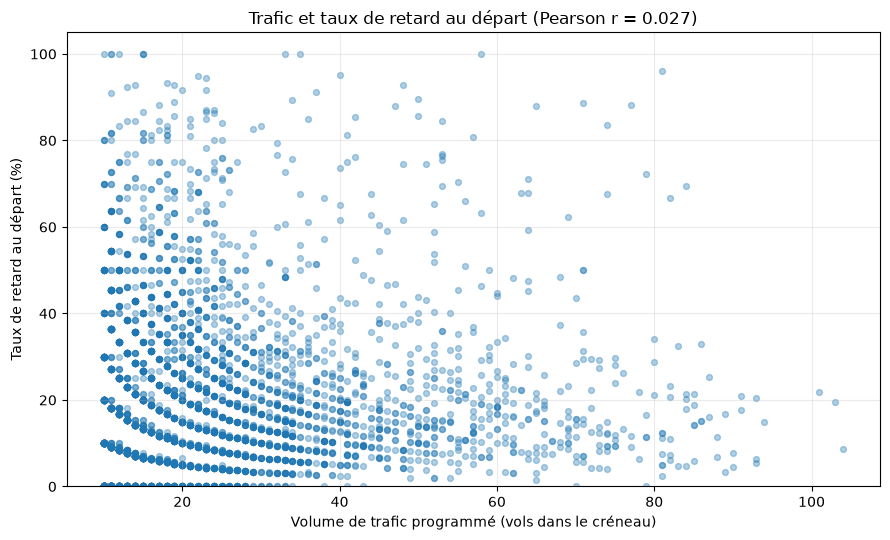

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


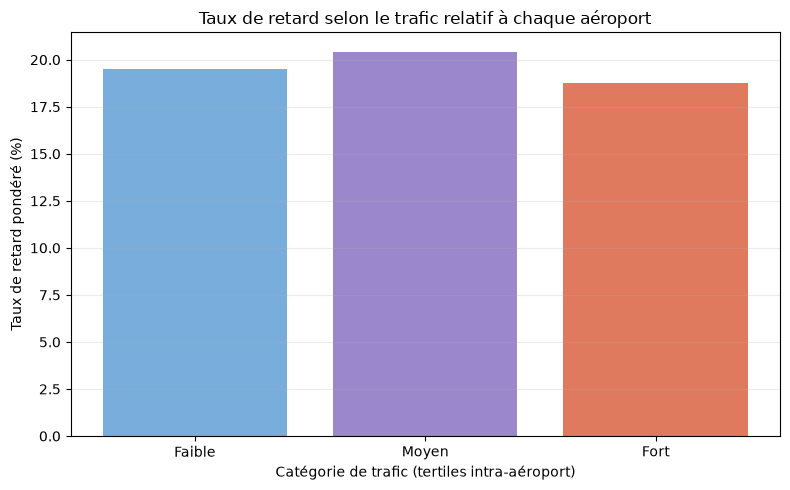

In [23]:
import matplotlib.pyplot as plt

# Graphique 1 : tirage aléatoire reproductible limité à 5 000 créneaux agrégés.
# Le seed 42 fixe le même tirage sur l'ensemble des aéroports et périodes.
scatter_df = (
    eligible_traffic
    .orderBy(F.rand(seed=42))
    .limit(5000)
    .toPandas()
)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(scatter_df["traffic_volume"], scatter_df["delay_rate"], alpha=0.35, s=18)
pearson_label = "n.d." if pearson_corr is None else f"{pearson_corr:.3f}"
ax.set_title(f"Trafic et taux de retard au départ (Pearson r = {pearson_label})")
ax.set_xlabel("Volume de trafic programmé (vols dans le créneau)")
ax.set_ylabel("Taux de retard au départ (%)")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Graphique 2 : barres pondérées selon les tertiles relatifs à chaque aéroport.
bar_df = spark.table("v_traffic_category_comparison").toPandas()
category_order = ["Faible", "Moyen", "Fort"]
bar_df["traffic_category"] = bar_df["traffic_category"].astype("category")
bar_df["traffic_category"] = bar_df["traffic_category"].cat.set_categories(category_order, ordered=True)
bar_df = bar_df.sort_values("traffic_category")

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(bar_df["traffic_category"].astype(str), bar_df["weighted_delay_rate"], color=["#79addc", "#9b87cc", "#e07a5f"])
ax.set_title("Taux de retard selon le trafic relatif à chaque aéroport")
ax.set_xlabel("Catégorie de trafic (tertiles intra-aéroport)")
ax.set_ylabel("Taux de retard pondéré (%)")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Interprétation métier

- **Question étudiée :** le taux de retard au départ augmente-t-il lorsque le volume de vols programmés dans un créneau aéroport–jour–heure est plus important ?
- **Méthode :** les vols sont agrégés par aéroport de départ, date et heure programmée. Les vols annulés restent comptés dans `traffic_volume`, mais ne sont pas observés pour le délai de départ. Un retard est compté à partir de 15 minutes. Les groupes comptant moins de 10 vols observés sont exclus des analyses statistiques. Ce filtre conserve 17,64 % des créneaux horaires, représentant 66,81 % des vols observés.
- **Résultat principal :** sur les créneaux éligibles, la corrélation de Pearson est de **0,0265** et celle de Spearman de **0,0687**. Ces deux valeurs proches de zéro indiquent une association très faible entre le volume programmé et le taux de retard. Dans ce périmètre, augmenter le nombre de vols prévus dans un créneau ne suffit donc pas à expliquer les retards au départ.
- **Comparaison intra-aéroport :** chaque aéroport est traité séparément avec trois tertiles (`Faible`, `Moyen`, `Fort`) calculés à partir de ses propres créneaux éligibles. Cette méthode évite qu'un grand aéroport domine uniquement par des volumes absolus élevés. Il faut conserver cette logique relative, car tous les aéroports n'ont pas la même activité.
- **Taux globaux pondérés :** les créneaux de trafic `Faible` présentent **19,52 %** de vols retardés (167 320 sur 857 067 observés), contre **20,43 %** pour `Moyen` (259 772 sur 1 271 267) et **18,74 %** pour `Fort` (318 411 sur 1 699 231). L'écart maximal est d'environ **1,70 point** entre les catégories `Moyen` et `Fort`; le trafic fort n'est donc pas associé au taux de retard le plus élevé dans ces données.
- **Implication opérationnelle :** il n'est pas justifié de déclencher une action de réduction des retards sur le seul critère du volume programmé. Le suivi doit plutôt croiser cette dimension avec l'aéroport, l'heure, la saison et d'autres facteurs opérationnels afin d'identifier les créneaux réellement à risque. Les catégories `Moyen` méritent ici une vigilance exploratoire, mais l'écart observé ne suffit pas à établir un seuil de pilotage.
- **Taux globaux :** chaque barre représente `SUM(delayed_flights) / SUM(observed_flights)`, pondéré par le nombre de vols observés. Ce calcul est préférable à la moyenne simple des pourcentages par créneau.
- **Lecture des graphiques :** le nuage de points représente les créneaux échantillonnés et permet de visualiser la dispersion autour de leur taux de retard; les barres comparent les catégories relatives pondérées.
- **Qualité et périmètre :** la table Gold contient **947 047 groupes** aéroport–jour–heure, les contrôles de cohérence indiquent **0 groupe invalide**, aucune heure programmée invalide n'a été filtrée et aucune valeur `2400` n'a été détectée. La conversion spéciale de fin de journée n'a donc pas été appliquée sur cette exécution.
- **Limites :** une corrélation ne démontre pas une causalité. `traffic_volume` est un indicateur de programmation issu du dataset, pas une mesure directe de la congestion réelle ou des temps d'attente. Les différences entre aéroports, les heures de pointe, les périodes de l'année, la météo, les contraintes opérationnelles et le trafic entrant peuvent influencer les résultats. De plus, le seuil de 10 vols observés exclut 82,36 % des créneaux horaires, représentant 33,19 % des vols observés. Les conclusions concernent donc principalement les créneaux suffisamment fréquentés.
- **Conclusion :** Dans le périmètre étudié, aucune augmentation systématique du taux de retard au départ n'est observée lorsque le volume de trafic programmé augmente. Les corrélations très faibles suggèrent que le nombre de vols programmés, considéré isolément, ne permet pas d'expliquer les variations du taux de retard. Une analyse complémentaire prenant en compte les caractéristiques propres à chaque aéroport, les horaires et les périodes de l'année serait nécessaire pour approfondir cette relation.

## 6. Analyse quotidienne des retards, des fêtes, d'un événement sportif et de la météo

On rapproche les fêtes de toutes les journées de vol et le Super Bowl XLIX du 1er février 2015 des départs de PHX, utilisé comme aéroport proxy de Phoenix. Les statistiques météo exploitent `weather_delay`, cause de retard fournie par le dataset, et non des relevés de température, vent ou précipitations.

Les tables Gold conservent le taux de retard, le taux d'annulation et les minutes de retard attribuées à la météo. Les causes ne sont comparées que sur les vols dont les cinq colonnes de cause sont renseignées. Ces résultats décrivent des associations et ne démontrent pas de causalité.


In [24]:
from pyspark.sql import functions as F

GOLD_DAILY_PATH = "/lakehouse/gold/flights_daily_stats"
GOLD_AIRPORT_EVENT_PATH = "/lakehouse/gold/flights_airport_event_weather_stats"

silver_daily = spark.read.format("delta").load(SILVER_MAIN_PATH)
delay_cause_columns = [
    "airline_delay",
    "weather_delay",
    "air_system_delay",
    "security_delay",
    "late_aircraft_delay",
]
missing_cause_columns = [column for column in delay_cause_columns if column not in silver_daily.columns]
if missing_cause_columns:
    raise ValueError(f"Colonnes de causes de retard absentes de Silver : {missing_cause_columns}")

known_arrival = (F.col("cancelled") == 0) & F.col("arrival_delay").isNotNull()
causes_complete = F.lit(True)
for column in delay_cause_columns:
    causes_complete = causes_complete & F.col(column).isNotNull()

cause_minutes = sum(
    (
        F.greatest(F.coalesce(F.col(column).cast("double"), F.lit(0.0)), F.lit(0.0))
        for column in delay_cause_columns
    ),
    F.lit(0.0),
)
weather_minutes = F.greatest(
    F.coalesce(F.col("weather_delay").cast("double"), F.lit(0.0)), F.lit(0.0)
)

def aggregate_daily(group_columns):
    return (
        silver_daily.groupBy(*group_columns)
        .agg(
            F.count("*").alias("scheduled_flights"),
            F.sum(F.when(F.col("cancelled") == 1, 1).otherwise(0)).alias("cancelled_flights"),
            F.sum(F.when(known_arrival, 1).otherwise(0)).alias("observed_flights"),
            F.sum(F.when(known_arrival & (F.col("arrival_delay") >= 15), 1).otherwise(0)).alias("delayed_flights"),
            F.percentile_approx(
                F.when(known_arrival, F.col("arrival_delay")), 0.5, 10000
            ).alias("median_arrival_delay"),
            F.sum(F.when(known_arrival & causes_complete, 1).otherwise(0)).alias("cause_documented_flights"),
            F.sum(
                F.when(known_arrival & causes_complete & (F.col("weather_delay") > 0), 1).otherwise(0)
            ).alias("weather_delay_flights"),
            F.sum(F.when(known_arrival & causes_complete, weather_minutes).otherwise(0.0)).alias(
                "weather_delay_minutes"
            ),
            F.sum(F.when(known_arrival & causes_complete, cause_minutes).otherwise(0.0)).alias(
                "attributed_delay_minutes"
            ),
        )
        .withColumn(
            "delay_rate",
            F.when(F.col("observed_flights") > 0, 100 * F.col("delayed_flights") / F.col("observed_flights")),
        )
        .withColumn(
            "cancellation_rate",
            100 * F.col("cancelled_flights") / F.col("scheduled_flights"),
        )
        .withColumn(
            "weather_delay_rate",
            F.when(
                F.col("cause_documented_flights") > 0,
                100 * F.col("weather_delay_flights") / F.col("cause_documented_flights"),
            ),
        )
        .withColumn(
            "weather_delay_share_pct",
            F.when(
                F.col("attributed_delay_minutes") > 0,
                100 * F.col("weather_delay_minutes") / F.col("attributed_delay_minutes"),
            ),
        )
    )

# Calendrier d'exemple : fêtes nationales et Super Bowl XLIX près de Phoenix.
# L'événement sportif est rapproché uniquement des départs de l'aéroport PHX.
events = [
    ("2015-01-01", "Nouvel An", "Fête", None, "National"),
    ("2015-02-01", "Super Bowl XLIX", "Sportif", "PHX", "Local · départ PHX (proxy Phoenix)"),
    ("2015-07-04", "Fête nationale", "Fête", None, "National"),
    ("2015-11-25", "Veille de Thanksgiving", "Fête", None, "National"),
    ("2015-11-26", "Thanksgiving", "Fête", None, "National"),
    ("2015-11-27", "Lendemain de Thanksgiving", "Fête", None, "National"),
    ("2015-12-25", "Noël", "Fête", None, "National"),
]
df_events = spark.createDataFrame(
    events, ["event_date", "event_name", "event_type", "airport_code", "event_scope"]
).withColumn("event_date", F.to_date("event_date"))
duplicate_event_keys = (
    df_events.groupBy("event_date", "airport_code").count().filter(F.col("count") > 1).count()
)
if duplicate_event_keys:
    raise ValueError(f"Clés date/aéroport dupliquées dans le calendrier : {duplicate_event_keys}")

# Gold nationale : événements sans aéroport associé (jours fériés).
df_daily = aggregate_daily(["flight_date"])
global_events = df_events.filter(F.col("airport_code").isNull()).drop("airport_code", "event_scope")
df_daily_events = (
    df_daily.join(
        F.broadcast(global_events), df_daily.flight_date == global_events.event_date, "left"
    )
    .drop("event_date")
    .withColumn("event_name", F.coalesce(F.col("event_name"), F.lit("Jour ordinaire")))
    .withColumn("event_type", F.coalesce(F.col("event_type"), F.lit("Jour ordinaire")))
)

# Gold aéroport/jour : événements nationaux partout, événement local à PHX seulement.
df_airport_daily = aggregate_daily(["origin_airport", "flight_date"])
df_airport_events = (
    df_airport_daily.alias("daily")
    .join(
        F.broadcast(df_events.alias("event")),
        (F.col("daily.flight_date") == F.col("event.event_date"))
        & (
            F.col("event.airport_code").isNull()
            | (F.col("daily.origin_airport") == F.col("event.airport_code"))
        ),
        "left",
    )
    .select(
        "daily.*",
        F.coalesce(F.col("event.event_name"), F.lit("Jour ordinaire")).alias("event_name"),
        F.coalesce(F.col("event.event_type"), F.lit("Jour ordinaire")).alias("event_type"),
        F.coalesce(F.col("event.event_scope"), F.lit("Aucun événement")).alias("event_scope"),
    )
)

df_daily_events.filter(F.col("event_name") != "Jour ordinaire").orderBy("flight_date").show(truncate=False)
df_airport_events.filter(F.col("event_name") != "Jour ordinaire").orderBy(
    "flight_date", "origin_airport"
).show(truncate=False)

# Comparaison des jeudis de novembre, sans conclure à une causalité.
thanksgiving_comparison = (
    df_daily_events.filter((F.month("flight_date") == 11) & (F.dayofweek("flight_date") == 5))
    .select(
        "flight_date", "event_name", "scheduled_flights", "observed_flights",
        "delayed_flights", "delay_rate", "cancellation_rate", "weather_delay_rate",
        "weather_delay_minutes", "weather_delay_share_pct",
    )
    .orderBy("flight_date")
)
thanksgiving_comparison.show(truncate=False)

# Écrire les deux tables Gold et les relire pour valider leur disponibilité Delta.
df_daily_events.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(GOLD_DAILY_PATH)
df_airport_events.write.format("delta").mode("overwrite").option("overwriteSchema", "true").save(
    GOLD_AIRPORT_EVENT_PATH
)
gold_daily = spark.read.format("delta").load(GOLD_DAILY_PATH)
gold_airport_events = spark.read.format("delta").load(GOLD_AIRPORT_EVENT_PATH)

assert gold_daily.count() == df_daily.count(), "La jointure événement a dupliqué des journées nationales."
assert gold_airport_events.count() == df_airport_daily.count(), "La jointure événement a dupliqué des groupes aéroport/jour."

invalid_daily = gold_daily.filter(
    (F.col("delayed_flights") > F.col("observed_flights"))
    | (F.col("observed_flights") > F.col("scheduled_flights"))
    | (F.col("cancelled_flights") > F.col("scheduled_flights"))
    | (F.col("weather_delay_flights") > F.col("cause_documented_flights"))
    | (F.col("weather_delay_minutes") > F.col("attributed_delay_minutes"))
    | (F.col("delay_rate").isNotNull() & ~F.col("delay_rate").between(0, 100))
    | (F.col("cancellation_rate").isNotNull() & ~F.col("cancellation_rate").between(0, 100))
    | (F.col("weather_delay_rate").isNotNull() & ~F.col("weather_delay_rate").between(0, 100))
    | (F.col("weather_delay_share_pct").isNotNull() & ~F.col("weather_delay_share_pct").between(0, 100))
)
invalid_count = invalid_daily.count()
assert invalid_count == 0, f"Incohérences détectées dans Gold : {invalid_count}"
weather_relation = (
    gold_airport_events.filter(F.col("cause_documented_flights") >= 10)
    .agg(
        F.count("*").alias("airport_days"),
        F.corr("weather_delay_rate", "delay_rate").alias("pearson_r"),
    )
    .first()
)
print(
    "Association descriptive météo attribuée / taux de retard (Pearson) : "
    f"r={weather_relation['pearson_r']} sur {weather_relation['airport_days']} groupes aéroport/jour."
)
print(f"Contrôles validés : {gold_daily.count()} dates nationales et {gold_airport_events.count()} groupes aéroport/jour.")
print("weather_delay mesure les minutes attribuées à la météo dans les dossiers de vol, pas les conditions météo observées.")
print(f"Tables Delta créées : {GOLD_DAILY_PATH} et {GOLD_AIRPORT_EVENT_PATH}")

+-----------+-----------------+-----------------+----------------+---------------+--------------------+------------------------+---------------------+---------------------+------------------------+------------------+-------------------+------------------+-----------------------+-------------------------+----------+
|flight_date|scheduled_flights|cancelled_flights|observed_flights|delayed_flights|median_arrival_delay|cause_documented_flights|weather_delay_flights|weather_delay_minutes|attributed_delay_minutes|delay_rate        |cancellation_rate  |weather_delay_rate|weather_delay_share_pct|event_name               |event_type|
+-----------+-----------------+-----------------+----------------+---------------+--------------------+------------------------+---------------------+---------------------+------------------------+------------------+-------------------+------------------+-----------------------+-------------------------+----------+
|2015-01-01 |13950            |466              |

+--------------+-----------+-----------------+-----------------+----------------+---------------+--------------------+------------------------+---------------------+---------------------+------------------------+------------------+------------------+------------------+-----------------------+----------+----------+-----------+
|origin_airport|flight_date|scheduled_flights|cancelled_flights|observed_flights|delayed_flights|median_arrival_delay|cause_documented_flights|weather_delay_flights|weather_delay_minutes|attributed_delay_minutes|delay_rate        |cancellation_rate |weather_delay_rate|weather_delay_share_pct|event_name|event_type|event_scope|
+--------------+-----------+-----------------+-----------------+----------------+---------------+--------------------+------------------------+---------------------+---------------------+------------------------+------------------+------------------+------------------+-----------------------+----------+----------+-----------+
|ABE           |

26/11/19 12:09:28 WARN MemoryManager: Total allocation exceeds 95.00% (2,040,109,440 bytes) of heap memory
Scaling row group sizes to 95.00% for 16 writers


Association descriptive météo attribuée / taux de retard (Pearson) : r=0.4554479209058671 sur 19128 groupes aéroport/jour.
Contrôles validés : 365 dates nationales et 111162 groupes aéroport/jour.
weather_delay mesure les minutes attribuées à la météo dans les dossiers de vol, pas les conditions météo observées.
Tables Delta créées : /lakehouse/gold/flights_daily_stats et /lakehouse/gold/flights_airport_event_weather_stats


### Interprétation métier

L'analyse quotidienne des vols américains de 2015 met en évidence des variations importantes du trafic et des retards selon les périodes de l'année.

**Thanksgiving**

Le 26 novembre 2015, jour de Thanksgiving, 10 068 vols étaient programmés, contre environ 16 600 lors des trois jeudis précédents, soit une diminution d'environ 39 %.

Le taux de retard à l'arrivée était également plus faible : **10,05 %**, contre **15,93 % à 20,77 %** les autres jeudis étudiés.

Le taux d'annulation était de **0,13 %**, contre **0,58 % à 1,60 %** les autres jeudis.

Ces résultats montrent que Thanksgiving se caractérise, dans notre dataset, par un trafic moins important et une meilleure ponctualité que les jeudis précédents.

**Autres événements**

La fête nationale américaine du 4 juillet présente également un taux de retard relativement faible (**7,83 %**).

À l'inverse, les premiers jours de janvier connaissent des taux de retard particulièrement élevés, atteignant **49,30 % le 4 janvier 2015**.

Ces observations suggèrent que les variations de ponctualité ne dépendent pas uniquement du nombre de vols programmés.

**Limites de l'analyse**

Les comparaisons portent uniquement sur l'année 2015 et sur un nombre limité d'événements.

Elles ne permettent pas d'établir que les fêtes provoquent directement une augmentation ou une diminution des retards.

Les conditions météorologiques, les caractéristiques des aéroports et les contraintes opérationnelles peuvent également influencer les résultats.

**Conclusion**

Cette analyse montre que les événements particuliers peuvent correspondre à des variations importantes du trafic et de la ponctualité, sans que ces deux indicateurs évoluent nécessairement dans le même sens.



## 6. Association entre météo NOAA et retards

Cette analyse mesure une association descriptive entre les conditions NOAA observées à l'heure du départ et le taux de retard. Les vols sont d'abord agrégés par aéroport de départ, date et heure météo UTC afin de ne pas surpondérer les créneaux très fréquentés.

La corrélation de Spearman est utilisée en priorité : elle mesure une relation monotone et résiste mieux à l'asymétrie des retards. Une corrélation ne démontre pas une causalité.

In [25]:
from pyspark.sql import Window, functions as F

weather_columns = [
    'origin_airport', 'flight_date', 'scheduled_departure_utc_hour',
    'air_temperature_c', 'wind_speed_mps', 'precipitation_1h_mm',
    'cancelled', 'arrival_delay',
]
silver_weather = spark.read.format("delta").load(SILVER_MAIN_PATH)
missing_weather_columns = [c for c in weather_columns if c not in silver_weather.columns]
if missing_weather_columns:
    raise ValueError(f"Colonnes météo absentes de Silver : {missing_weather_columns}")

weather_groups = (
    silver_weather.select(*weather_columns)
    .groupBy(
        'origin_airport', 'flight_date', 'scheduled_departure_utc_hour',
        'air_temperature_c', 'wind_speed_mps', 'precipitation_1h_mm',
    )
    .agg(
        F.sum(F.when((F.col('cancelled') == 0) & F.col('arrival_delay').isNotNull(), 1).otherwise(0)).alias('observed_flights'),
        F.sum(F.when((F.col('cancelled') == 0) & (F.col('arrival_delay') >= 15), 1).otherwise(0)).alias('delayed_flights'),
    )
    .filter(
        (F.col('observed_flights') >= 10)
        & F.col('air_temperature_c').isNotNull()
        & F.col('wind_speed_mps').isNotNull()
        & F.col('precipitation_1h_mm').isNotNull()
    )
    .withColumn('delay_rate', 100 * F.col('delayed_flights') / F.col('observed_flights'))
)

rank_window = Window.orderBy(F.col("wind_speed_mps"))
delay_rank_window = Window.orderBy(F.col("delay_rate"))
weather_groups = (
    weather_groups
    .withColumn("wind_rank", F.percent_rank().over(rank_window))
    .withColumn("delay_rank", F.percent_rank().over(delay_rank_window))
)
weather_association = weather_groups.agg(
    F.count("*").alias("airport_hour_groups"),
    F.corr("wind_rank", "delay_rank").alias("spearman_wind_delay"),
    F.corr("air_temperature_c", "delay_rate").alias("pearson_temperature_delay"),
    F.avg(F.when(F.col("precipitation_1h_mm") > 0, F.col("delay_rate"))).alias("rain_delay_rate"),
    F.avg(F.when(F.col("precipitation_1h_mm") <= 0, F.col("delay_rate"))).alias("dry_delay_rate"),
).first()
weather_association


26/11/19 12:09:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:33 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 12:09:34 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/19 1

Row(airport_hour_groups=151050, spearman_wind_delay=0.16045367031321559, pearson_temperature_delay=-0.016732894180803672, rain_delay_rate=38.5242539372183, dry_delay_rate=18.996163627502334)

26/11/19 12:12:28 WARN JavaUtils: Attempt to delete using native Unix OS command failed for path = /tmp/blockmgr-917699cb-0084-47bb-bad4-b0d36716f2c1. Falling back to Java IO way
java.io.IOException: Failed to delete: /tmp/blockmgr-917699cb-0084-47bb-bad4-b0d36716f2c1
	at org.apache.spark.network.util.JavaUtils.deleteRecursivelyUsingUnixNative(JavaUtils.java:354)
	at org.apache.spark.network.util.JavaUtils.deleteRecursively(JavaUtils.java:271)
	at org.apache.spark.network.util.JavaUtils.deleteRecursively(JavaUtils.java:250)
	at org.apache.spark.util.SparkFileUtils.deleteRecursively(SparkFileUtils.scala:158)
	at org.apache.spark.util.SparkFileUtils.deleteRecursively$(SparkFileUtils.scala:157)
	at org.apache.spark.util.Utils$.deleteRecursively(Utils.scala:1062)
	at org.apache.spark.storage.DiskBlockManager.$anonfun$doStop$1(DiskBlockManager.scala:372)
	at org.apache.spark.storage.DiskBlockManager.$anonfun$doStop$1$adapted(DiskBlockManager.scala:368)
	at scala.collection.ArrayOps$.foreach